# Análisis Exploratorio de Datos
## Vigilancia epidemiológica del dengue — Bucaramanga 2015–2025

**Fuente:** SIVIGILA — Instituto Nacional de Salud, Colombia  
**Cohorte:** 28,626 casos notificados · 82 variables · 11 años de seguimiento

---

El análisis exploratorio en datos de vigilancia epidemiológica no es un paso
descriptivo menor: es el mecanismo principal para detectar artefactos del sistema
de notificación que, si no se corrigen, producen modelos que aprenden patrones
espurios en lugar de señales clínicas reales.

En el contexto de SIVIGILA, los riesgos específicos son:
- **Inconsistencias entre campos relacionados** (PAC_HOS_ vs FEC_HOS_ vs CONDUCTA)
- **Cambios de protocolo no documentados** que generan rupturas temporales
- **Variaciones en la completitud del reporte** según municipio y año
- **Valores centinela** (ej. 1900-01-01 en FEC_DEF_) que el sistema usa como 'sin dato'

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
import joblib
from pathlib import Path
from datetime import datetime

warnings.filterwarnings('ignore')
%matplotlib inline

# Configuración visual para figuras de calidad de publicación
# dpi=300 es el estándar mínimo para journals biomédicos (Q1)
plt.rcParams.update({
    'figure.dpi': 150,          # pantalla
    'savefig.dpi': 300,         # exportación
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.frameon': False,
    'legend.fontsize': 10,
})
sns.set_theme(style='whitegrid', font_scale=1.05)

# Paleta del proyecto — consistente entre todos los notebooks
COLORS = {
    'primary':    '#2C7BB6',   # azul: no hospitalizado
    'secondary':  '#D7191C',   # rojo: hospitalizado
    'accent':     '#FDAE61',   # naranja: destacados
    'neutral':    '#7F7F7F',   # gris: referencias
    'con_signos': '#E74C3C',   # DCSA
    'sin_signos': '#3498DB',   # DSSA
    'grave':      '#8E44AD',   # dengue grave
}

# Variables clínicas definidas por la clasificación OMS 2009
# adoptada por el INS Colombia mediante Circular 0058 de 2010
SIGNOS_ALARMA = [
    'DOLOR_ABDO', 'VOMITO', 'DIARREA', 'SOMNOLENCI',
    'HIPOTENSIO', 'HEPATOMEG', 'HEM_MUCOSA',
    'HIPOTERMIA', 'AUM_HEMATO', 'CAIDA_PLAQ', 'ACUM_LIQUI'
]
SINTOMAS_GENERALES = [
    'FIEBRE', 'CEFALEA', 'DOLRRETROO', 'MALGIAS', 'ARTRALGIA', 'ERUPCIONR'
]
TARGET = 'TARGET_HOSPITALIZACION_ORIGINAL'

# Rutas relativas al notebook — funcionan sin configuración previa
NB_DIR      = Path('.')
ROOT = Path(r'D:\Documentos\GitHub\dengue')  # <-- edita aqui
OUT_FIG     = ROOT / 'outputs' / 'figures'
OUT_TAB     = ROOT / 'outputs' / 'tables'
INTERIM     = ROOT / 'data' / 'interim'
CHECKPOINTS = ROOT / 'outputs' / 'checkpoints'

for p in [OUT_FIG, OUT_TAB, INTERIM, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)

print('Entorno listo')

Entorno listo


In [6]:
print(ROOT)

D:\Documentos\GitHub\dengue


In [7]:
# Carga de datos
# El archivo ya fue depurado: fechas parseadas, TARGET construido, CLASFINAL corregida
# Se busca el CSV en data/raw/ relativo a la raíz del repositorio
CSV = ROOT / 'data' / 'raw' / 'datos_dengue_bucaramanga_depurado.csv'

if not CSV.exists():
    # Buscar en uploads de Colab / ruta alternativa
    alternativas = [
        Path('/content/drive/MyDrive/datos_dengue_bucaramanga_depurado.csv'),
        Path('/content/datos_dengue_bucaramanga_depurado.csv'),
        Path('datos_dengue_bucaramanga_depurado.csv'),
    ]
    for alt in alternativas:
        if alt.exists():
            CSV = alt
            break
    else:
        raise FileNotFoundError(
            f'CSV no encontrado.\n'
            f'Copia datos_dengue_bucaramanga_depurado.csv a:\n  {ROOT / "data" / "raw"}')

df = pd.read_csv(CSV, encoding='utf-8-sig', low_memory=False)

# Parsear fechas que quedaron como string en el CSV depurado
for col in ['FEC_NOT_DT','FEC_CON__DT','INI_SIN__DT','FEC_HOS__DT','FEC_DEF__DT']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

print(f'Registros  : {df.shape[0]:,}')
print(f'Variables  : {df.shape[1]}')
print(f'Periodo    : {df["AÑO"].min()} – {df["AÑO"].max()}')
print(f'Memoria    : {df.memory_usage(deep=True).sum()/1e6:.1f} MB')

Registros  : 28,626
Variables  : 82
Periodo    : 2015 – 2025
Memoria    : 24.9 MB


## 1. Distribución de la variable objetivo

De los 28,626 casos notificados, **9,037 (31.6%) fueron hospitalizados**.
Este desbalance global varía drásticamente según la clasificación clínica:
el 64.8% de los casos *con signos de alarma* se hospitalizan frente a solo
el 3.9% de los casos *sin signos*, lo que justifica construir modelos
separados por estrato clínico en lugar de un modelo único.

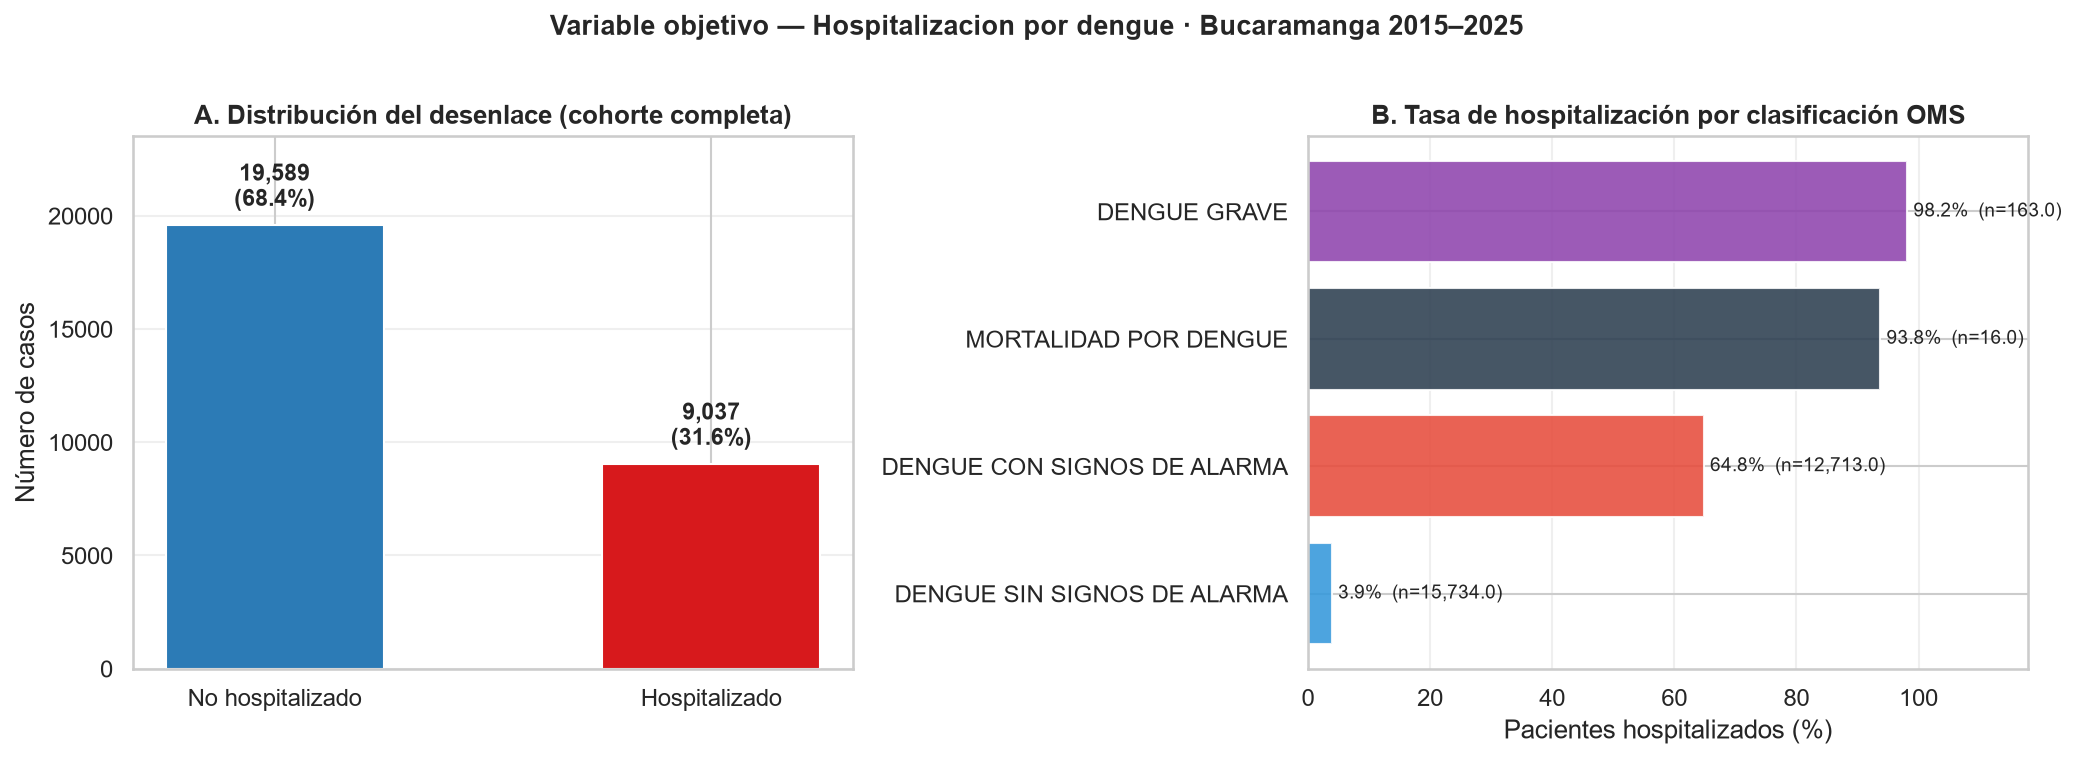

In [8]:
# Distribución del TARGET y de CLASFINAL
# La clasificación clínica final (CLASFINAL) es el principal determinante
# de la hospitalización y define los estratos para el modelado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A — distribución global
ax = axes[0]
conteos = df[TARGET].value_counts().sort_index()
barras  = ax.bar(['No hospitalizado', 'Hospitalizado'],
    conteos.values,
    color=[COLORS['primary'], COLORS['secondary']],
    width=0.5, edgecolor='white')
ax.bar_label(barras,
    labels=[f'{v:,}\n({v/len(df)*100:.1f}%)' for v in conteos.values],
    padding=6, fontsize=11, fontweight='bold')
ax.set_title('A. Distribución del desenlace (cohorte completa)')
ax.set_ylabel('Número de casos')
ax.set_ylim(0, conteos.max() * 1.2)
ax.grid(axis='y', alpha=0.3)

# Panel B — tasa de hospitalización por clasificación clínica
ax = axes[1]
hosp_clase = (
    df.groupby('CLASFINAL')[TARGET]
    .agg(N='size', Hosp='sum')
    .assign(Pct=lambda x: x['Hosp'] / x['N'] * 100)
    .sort_values('Pct', ascending=True)
)
pal = {'DENGUE SIN SIGNOS DE ALARMA': COLORS['sin_signos'],
       'DENGUE CON SIGNOS DE ALARMA': COLORS['con_signos'],
       'DENGUE GRAVE': COLORS['grave'],
       'MORTALIDAD POR DENGUE': '#2C3E50'}
colores_b = [pal.get(c, COLORS['neutral']) for c in hosp_clase.index]
bars = ax.barh(hosp_clase.index, hosp_clase['Pct'],
    color=colores_b, alpha=0.88, edgecolor='white')
for bar, (_, row) in zip(bars, hosp_clase.iterrows()):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
        f"{row['Pct']:.1f}%  (n={row['N']:,})",
        va='center', fontsize=9)
ax.set_title('B. Tasa de hospitalización por clasificación OMS')
ax.set_xlabel('Pacientes hospitalizados (%)')
ax.set_xlim(0, 118)
ax.grid(axis='x', alpha=0.3)

plt.suptitle('Variable objetivo — Hospitalizacion por dengue · Bucaramanga 2015–2025',
    fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(OUT_FIG / '01_distribucion_target.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()

## 2. Evolución temporal

La tasa de hospitalización creció de forma sostenida: del 11.7% en 2015
al 60.4% en 2022, con una caída posterior al 31–40% en 2023–2025.
Este incremento no refleja necesariamente mayor gravedad clínica: puede
responder a cambios en el protocolo de clasificación del INS y a la
incorporación de criterios más estrictos de manejo intrahospitalario.
La covariable `AÑO` debe incluirse en los modelos para evitar que
este efecto de período confunda la estimación de los predictores clínicos.

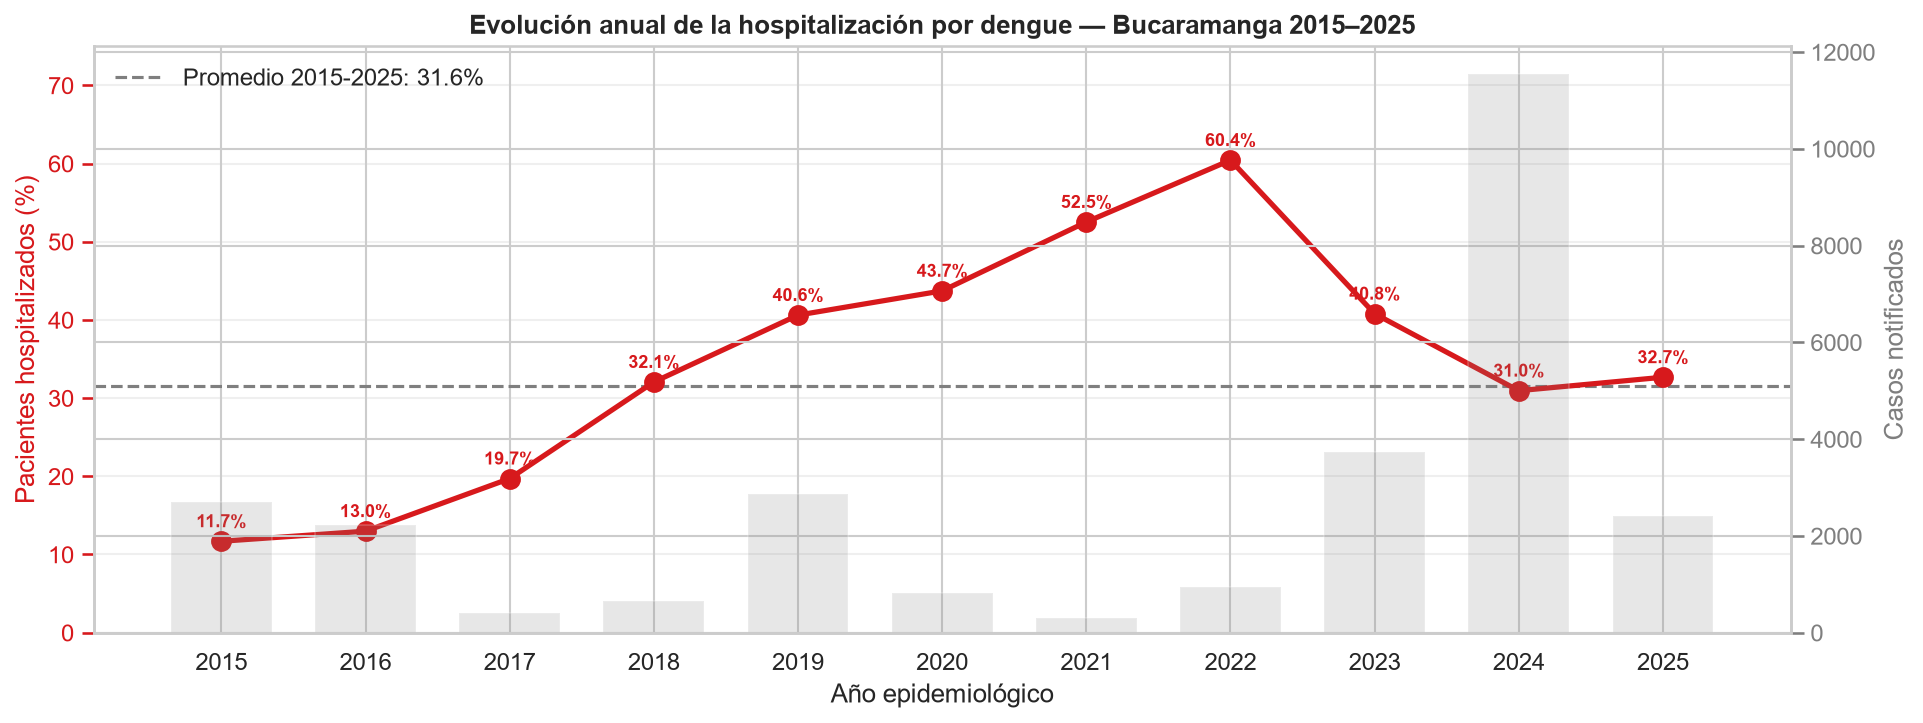

,Total,Hosp,Pct
AÑO,,,
2015,2695,315,11.688312
2016,2234,290,12.981200
2017,411,81,19.708029
2018,655,210,32.061069
2019,2856,1160,40.616246
2020,828,362,43.719807
2021,297,156,52.525253
2022,953,576,60.440714
2023,3738,1525,40.797218


In [9]:
# Evolución anual de hospitalización
# La inclusión de AÑO como covariable no es opcional:
# sin ella, el modelo puede aprender el año como proxy de la conducta médica
# en lugar de aprender la señal clínica del paciente
hosp_anual = (
    df.groupby('AÑO')[TARGET]
    .agg(Total='size', Hosp='sum')
    .assign(Pct=lambda x: x['Hosp'] / x['Total'] * 100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(13, 5))

# Barras de volumen (eje secundario)
ax2 = ax.twinx()
ax2.bar(hosp_anual['AÑO'], hosp_anual['Total'],
    color=COLORS['neutral'], alpha=0.18, width=0.7, label='N casos')
ax2.set_ylabel('Casos notificados', color=COLORS['neutral'])
ax2.tick_params(axis='y', colors=COLORS['neutral'])
ax2.spines['top'].set_visible(False)

# Línea de tasa
ax.plot(hosp_anual['AÑO'], hosp_anual['Pct'],
    marker='o', linewidth=2.5, markersize=9,
    color=COLORS['secondary'], zorder=5)
for _, r in hosp_anual.iterrows():
    ax.text(r['AÑO'], r['Pct'] + 1.8, f"{r['Pct']:.1f}%",
        ha='center', fontsize=8.5, fontweight='bold', color=COLORS['secondary'])

# Promedio general
pct_gral = df[TARGET].mean() * 100
ax.axhline(pct_gral, linestyle='--', linewidth=1.5,
    color=COLORS['neutral'], label=f'Promedio 2015-2025: {pct_gral:.1f}%')

ax.set_title('Evolución anual de la hospitalización por dengue — Bucaramanga 2015–2025')
ax.set_xlabel('Año epidemiológico')
ax.set_ylabel('Pacientes hospitalizados (%)', color=COLORS['secondary'])
ax.tick_params(axis='y', colors=COLORS['secondary'])
ax.set_ylim(0, 75)
ax.set_xticks(hosp_anual['AÑO'])
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
fig.savefig(OUT_FIG / '02_evolucion_temporal.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()
display(hosp_anual.set_index('AÑO'))

## 3. Perfil sociodemográfico

La cohorte es prácticamente equitativa en sexo (51.4% M / 48.6% F).
El estrato socioeconómico muestra concentración en estratos 2 y 3 (77.7%),
coherente con la distribución urbana de Bucaramanga. El régimen contributivo
concentra el 68% de los casos, reflejando la composición aseguradora
de una ciudad intermedia con alta formalidad laboral.

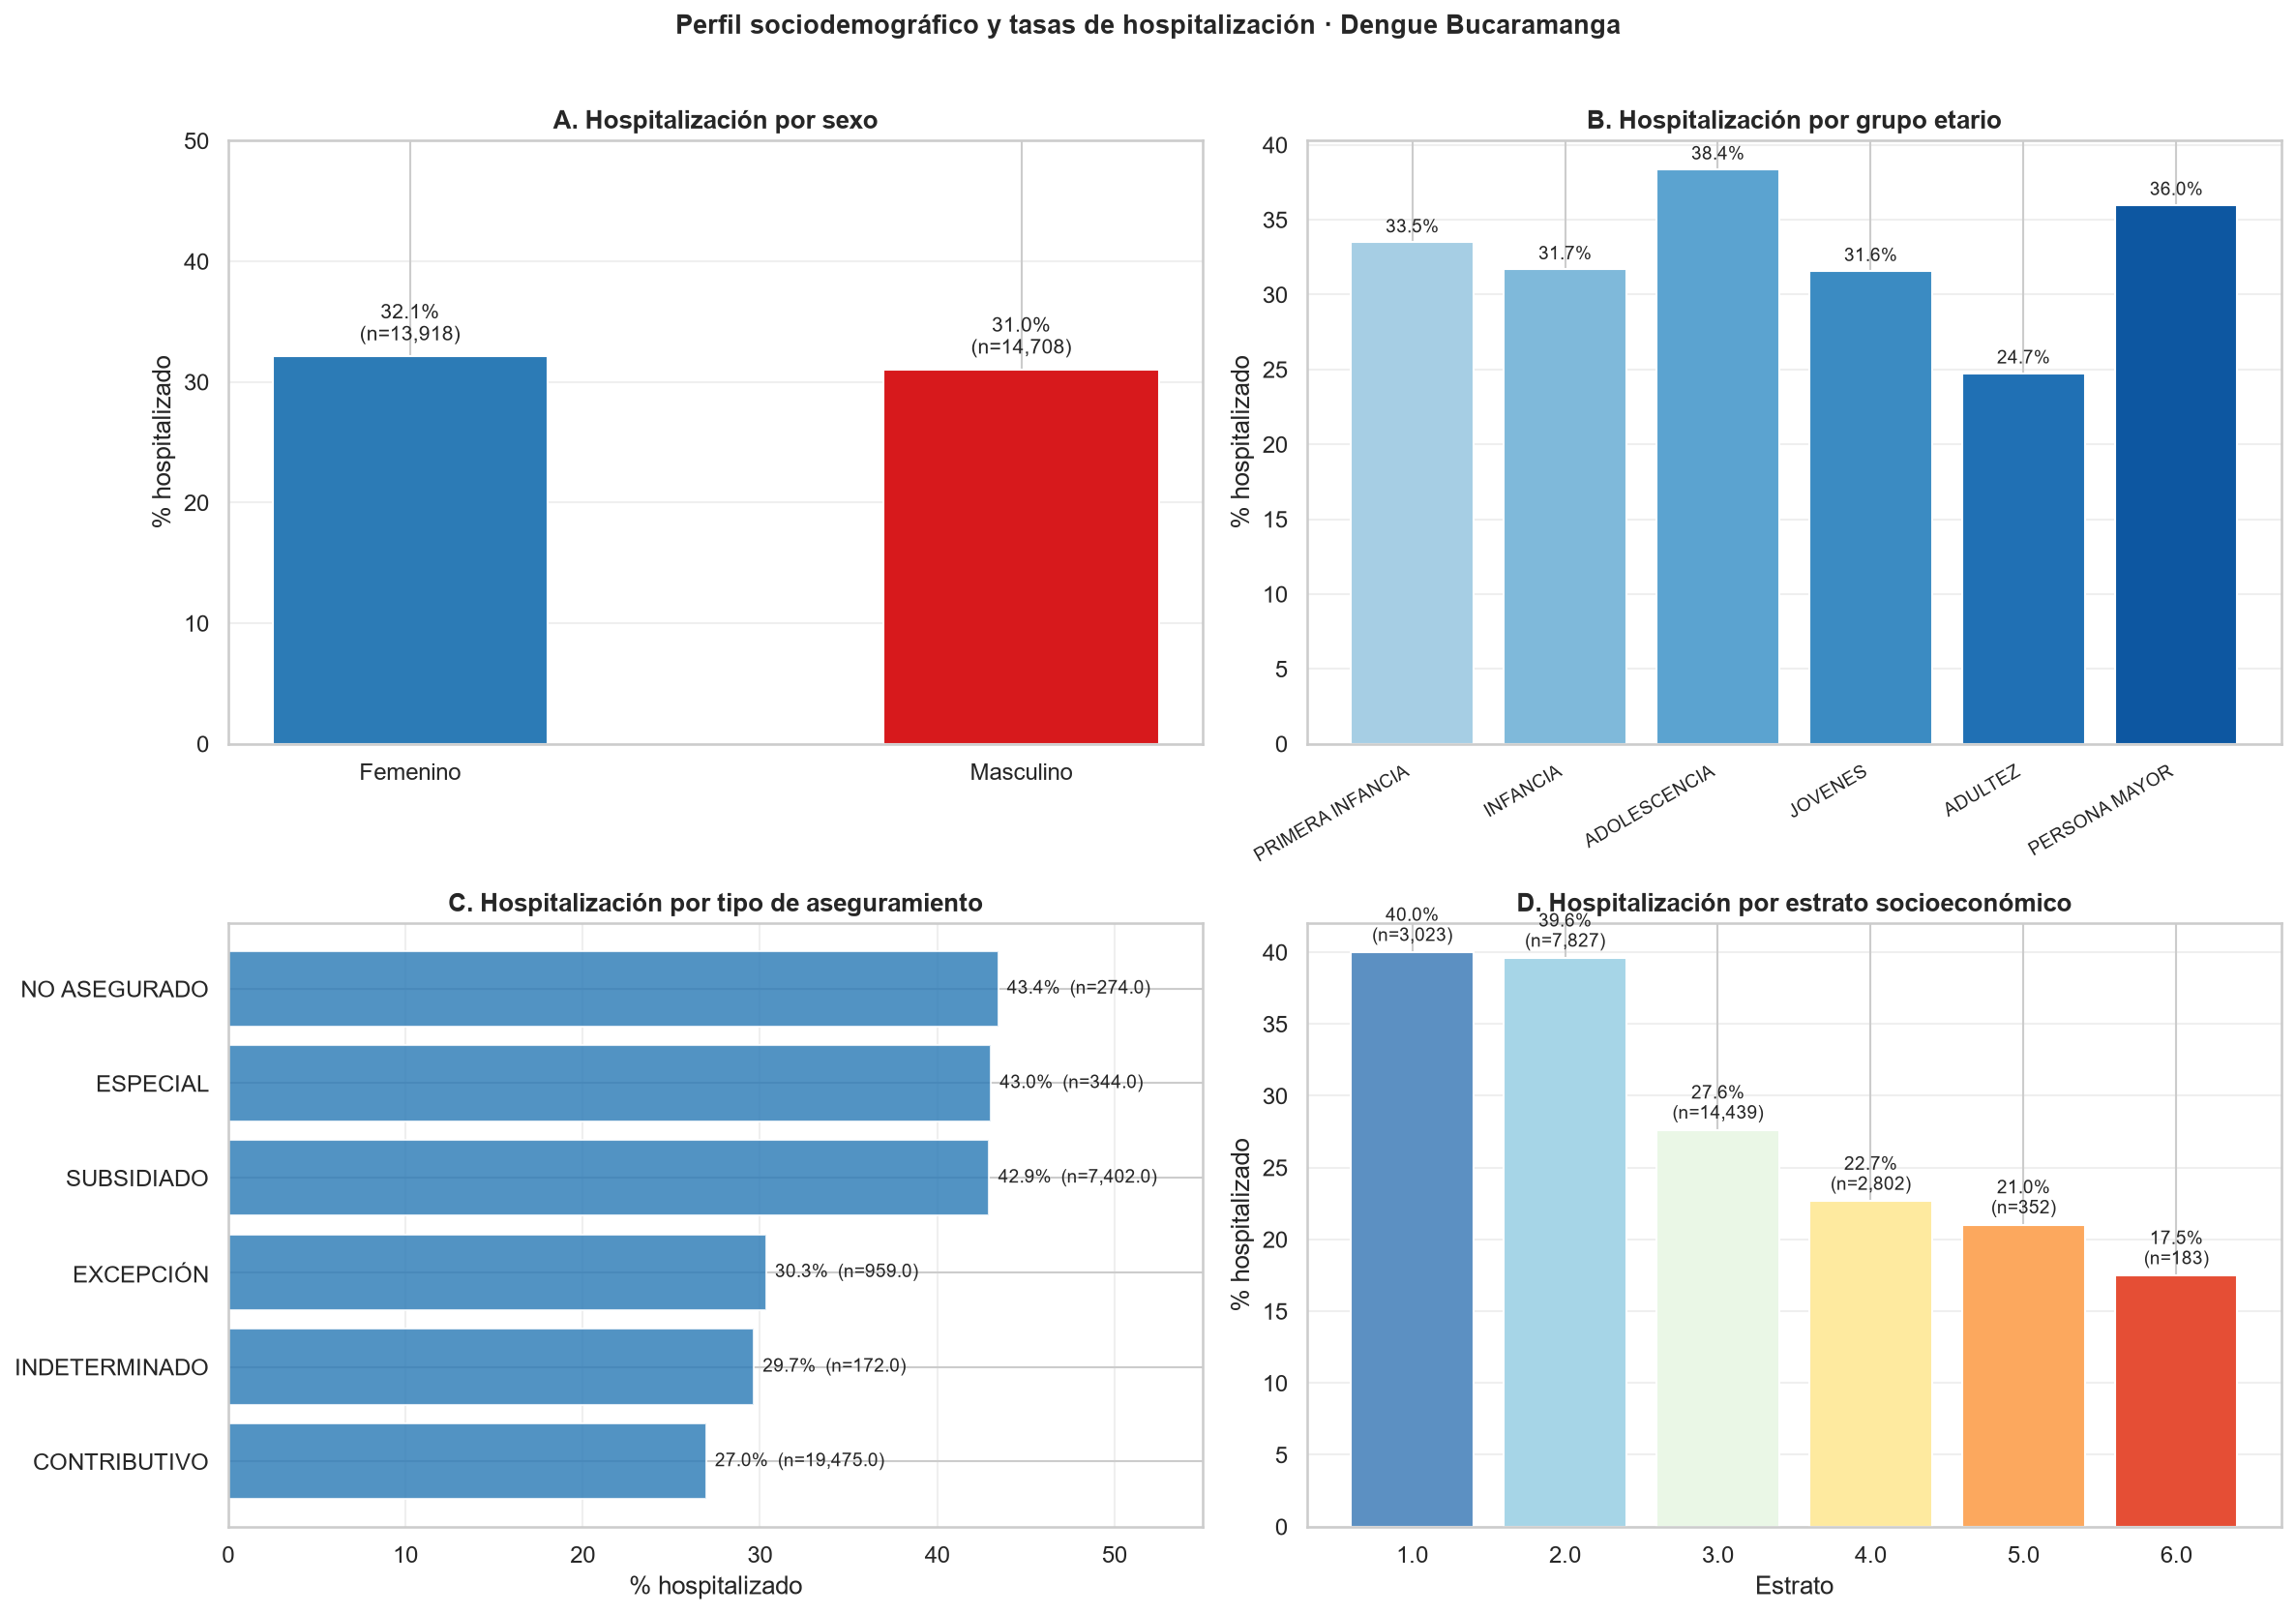

In [10]:
# Perfil sociodemográfico con tasas de hospitalización por subgrupo
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# ── A: Sexo ──────────────────────────────────────────────────────────────────
ax = axes[0, 0]
sexo_hosp = (
    df.groupby('SEXO_')[TARGET]
    .agg(N='size', Hosp='sum')
    .assign(Pct=lambda x: x['Hosp'] / x['N'] * 100)
)
sexo_hosp.index = sexo_hosp.index.map({'M': 'Masculino', 'F': 'Femenino'})
bars = ax.bar(sexo_hosp.index, sexo_hosp['Pct'],
    color=[COLORS['primary'], COLORS['secondary']],
    width=0.45, edgecolor='white')
ax.bar_label(bars,
    labels=[f"{p:.1f}%\n(n={n:,})" for p, n in zip(sexo_hosp['Pct'], sexo_hosp['N'])],
    padding=5, fontsize=10)
ax.set_title('A. Hospitalización por sexo')
ax.set_ylabel('% hospitalizado')
ax.set_ylim(0, 50)
ax.grid(axis='y', alpha=0.3)

# ── B: Grupo etario ───────────────────────────────────────────────────────────
ax = axes[0, 1]
orden_edad = ['PRIMERA INFANCIA','INFANCIA','ADOLESCENCIA','JOVENES','ADULTEZ','PERSONA MAYOR']
etario = (
    df.groupby('DEF_CLAS_EDAD')[TARGET]
    .agg(N='size', Hosp='sum')
    .assign(Pct=lambda x: x['Hosp'] / x['N'] * 100)
    .reindex([e for e in orden_edad if e in df['DEF_CLAS_EDAD'].unique()])
)
bars = ax.bar(range(len(etario)), etario['Pct'],
    color=[plt.cm.Blues(0.35 + i * 0.1) for i in range(len(etario))],
    edgecolor='white')
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9)
ax.set_xticks(range(len(etario)))
ax.set_xticklabels(etario.index, rotation=30, ha='right', fontsize=9)
ax.set_title('B. Hospitalización por grupo etario')
ax.set_ylabel('% hospitalizado')
ax.grid(axis='y', alpha=0.3)

# ── C: Tipo de aseguramiento ──────────────────────────────────────────────────
ax = axes[1, 0]
ss = (
    df.groupby('TIP_SS_')[TARGET]
    .agg(N='size', Hosp='sum')
    .assign(Pct=lambda x: x['Hosp'] / x['N'] * 100)
    .sort_values('Pct', ascending=True)
)
bars = ax.barh(ss.index, ss['Pct'],
    color=COLORS['primary'], alpha=0.82, edgecolor='white')
for bar, (idx, row) in zip(bars, ss.iterrows()):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
        f"{row['Pct']:.1f}%  (n={row['N']:,})", va='center', fontsize=9)
ax.set_title('C. Hospitalización por tipo de aseguramiento')
ax.set_xlabel('% hospitalizado')
ax.set_xlim(0, 55)
ax.grid(axis='x', alpha=0.3)

# ── D: Estrato socioeconómico ─────────────────────────────────────────────────
ax = axes[1, 1]
est = (
    df.groupby('ESTRATO_')[TARGET]
    .agg(N='size', Hosp='sum')
    .assign(Pct=lambda x: x['Hosp'] / x['N'] * 100)
    .reset_index()
)
bars = ax.bar(est['ESTRATO_'].astype(str), est['Pct'],
    color=[plt.cm.RdYlBu_r(0.15 + i * 0.14) for i in range(len(est))],
    edgecolor='white')
ax.bar_label(bars,
    labels=[f"{p:.1f}%\n(n={n:,})" for p, n in zip(est['Pct'], est['N'])],
    padding=3, fontsize=9)
ax.set_title('D. Hospitalización por estrato socioeconómico')
ax.set_xlabel('Estrato')
ax.set_ylabel('% hospitalizado')
ax.grid(axis='y', alpha=0.3)

plt.suptitle('Perfil sociodemográfico y tasas de hospitalización · Dengue Bucaramanga',
    fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(OUT_FIG / '03_perfil_sociodemografico.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()

## 4. Prevalencia de manifestaciones clínicas

Las variables clínicas no tienen valores nulos (0 NaN en los 17 campos),
lo que indica que el formulario SIVIGILA fuerza respuesta binaria (1=sí / 2=no).
La fiebre (83.5%) y mialgia (71.3%) son los síntomas más prevalentes.
Entre los signos de alarma, caída de plaquetas (15.9%) y dolor abdominal (15.0%)
son los más frecuentes — ambos con alta capacidad discriminativa para hospitalización.

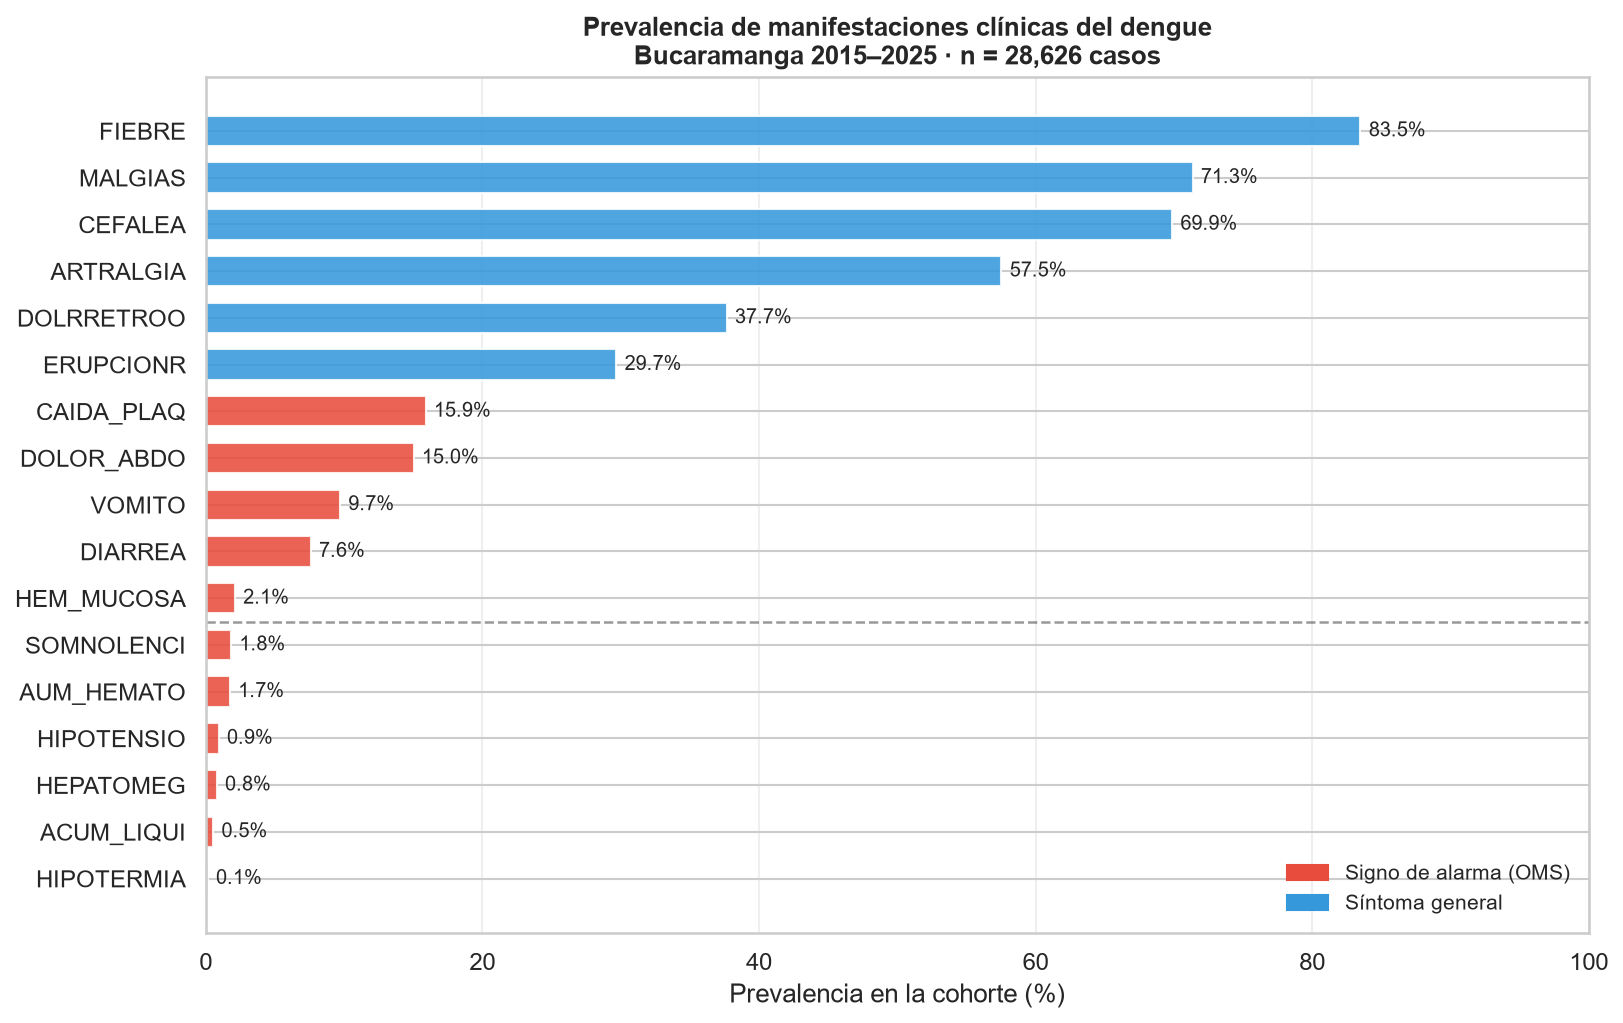

,Variable,Tipo,Prevalencia_%
16,FIEBRE,Sintoma general,83.49
15,MALGIAS,Sintoma general,71.35
14,CEFALEA,Sintoma general,69.87
13,ARTRALGIA,Sintoma general,57.53
12,DOLRRETROO,Sintoma general,37.66
11,ERUPCIONR,Sintoma general,29.68
10,CAIDA_PLAQ,Signo de alarma,15.89
9,DOLOR_ABDO,Signo de alarma,15.02
8,VOMITO,Signo de alarma,9.70
7,DIARREA,Signo de alarma,7.58


In [11]:
# Prevalencia de manifestaciones clínicas
# Codificación SIVIGILA: 1 = presente, 2 = ausente
# La ausencia de NaN confirma que el formulario exige respuesta obligatoria
todas = SINTOMAS_GENERALES + SIGNOS_ALARMA
prev  = (df[todas].eq(1).mean() * 100).sort_values(ascending=True)
tipos = ['Sintoma general' if v in SINTOMAS_GENERALES else 'Signo de alarma'
    for v in prev.index]

fig, ax = plt.subplots(figsize=(11, 7))

colores_b = [COLORS['con_signos'] if t == 'Signo de alarma'
    else COLORS['sin_signos'] for t in tipos]

bars = ax.barh(prev.index, prev.values, color=colores_b, alpha=0.87,
    edgecolor='white', height=0.65)
ax.bar_label(bars, fmt='%.1f%%', padding=4, fontsize=9.5)

# Separador visual entre grupos
n_sint = len(SINTOMAS_GENERALES)
ax.axhline(n_sint - 0.5, color='black', linewidth=1.2, linestyle='--', alpha=0.4)

ax.set_xlabel('Prevalencia en la cohorte (%)')
ax.set_title(
    'Prevalencia de manifestaciones clínicas del dengue\n'
    'Bucaramanga 2015–2025 · n = 28,626 casos')
ax.set_xlim(0, 100)
ax.grid(axis='x', alpha=0.3)

leyenda = [
    mpatches.Patch(color=COLORS['con_signos'], label='Signo de alarma (OMS)'),
    mpatches.Patch(color=COLORS['sin_signos'], label='Síntoma general'),
]
ax.legend(handles=leyenda, loc='lower right', fontsize=10)
plt.tight_layout()
fig.savefig(OUT_FIG / '04_prevalencia_clinica.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()

# Exportar tabla
tabla_prev = pd.DataFrame({'Variable': prev.index, 'Tipo': tipos, 'Prevalencia_%': prev.values.round(2)})
tabla_prev.to_csv(OUT_TAB / 'prevalencia_clinica.csv', index=False)
display(tabla_prev.sort_values('Prevalencia_%', ascending=False))

## 5. Correlación entre manifestaciones clínicas

La correlación phi (equivalente de Pearson para variables binarias) revela
la redundancia de información entre síntomas. Alta correlación entre
dos variables no invalida su uso en modelos de árboles (que manejan
colinealidad de forma natural), pero sí impacta los modelos lineales
y la interpretabilidad de los coeficientes de regresión logística.

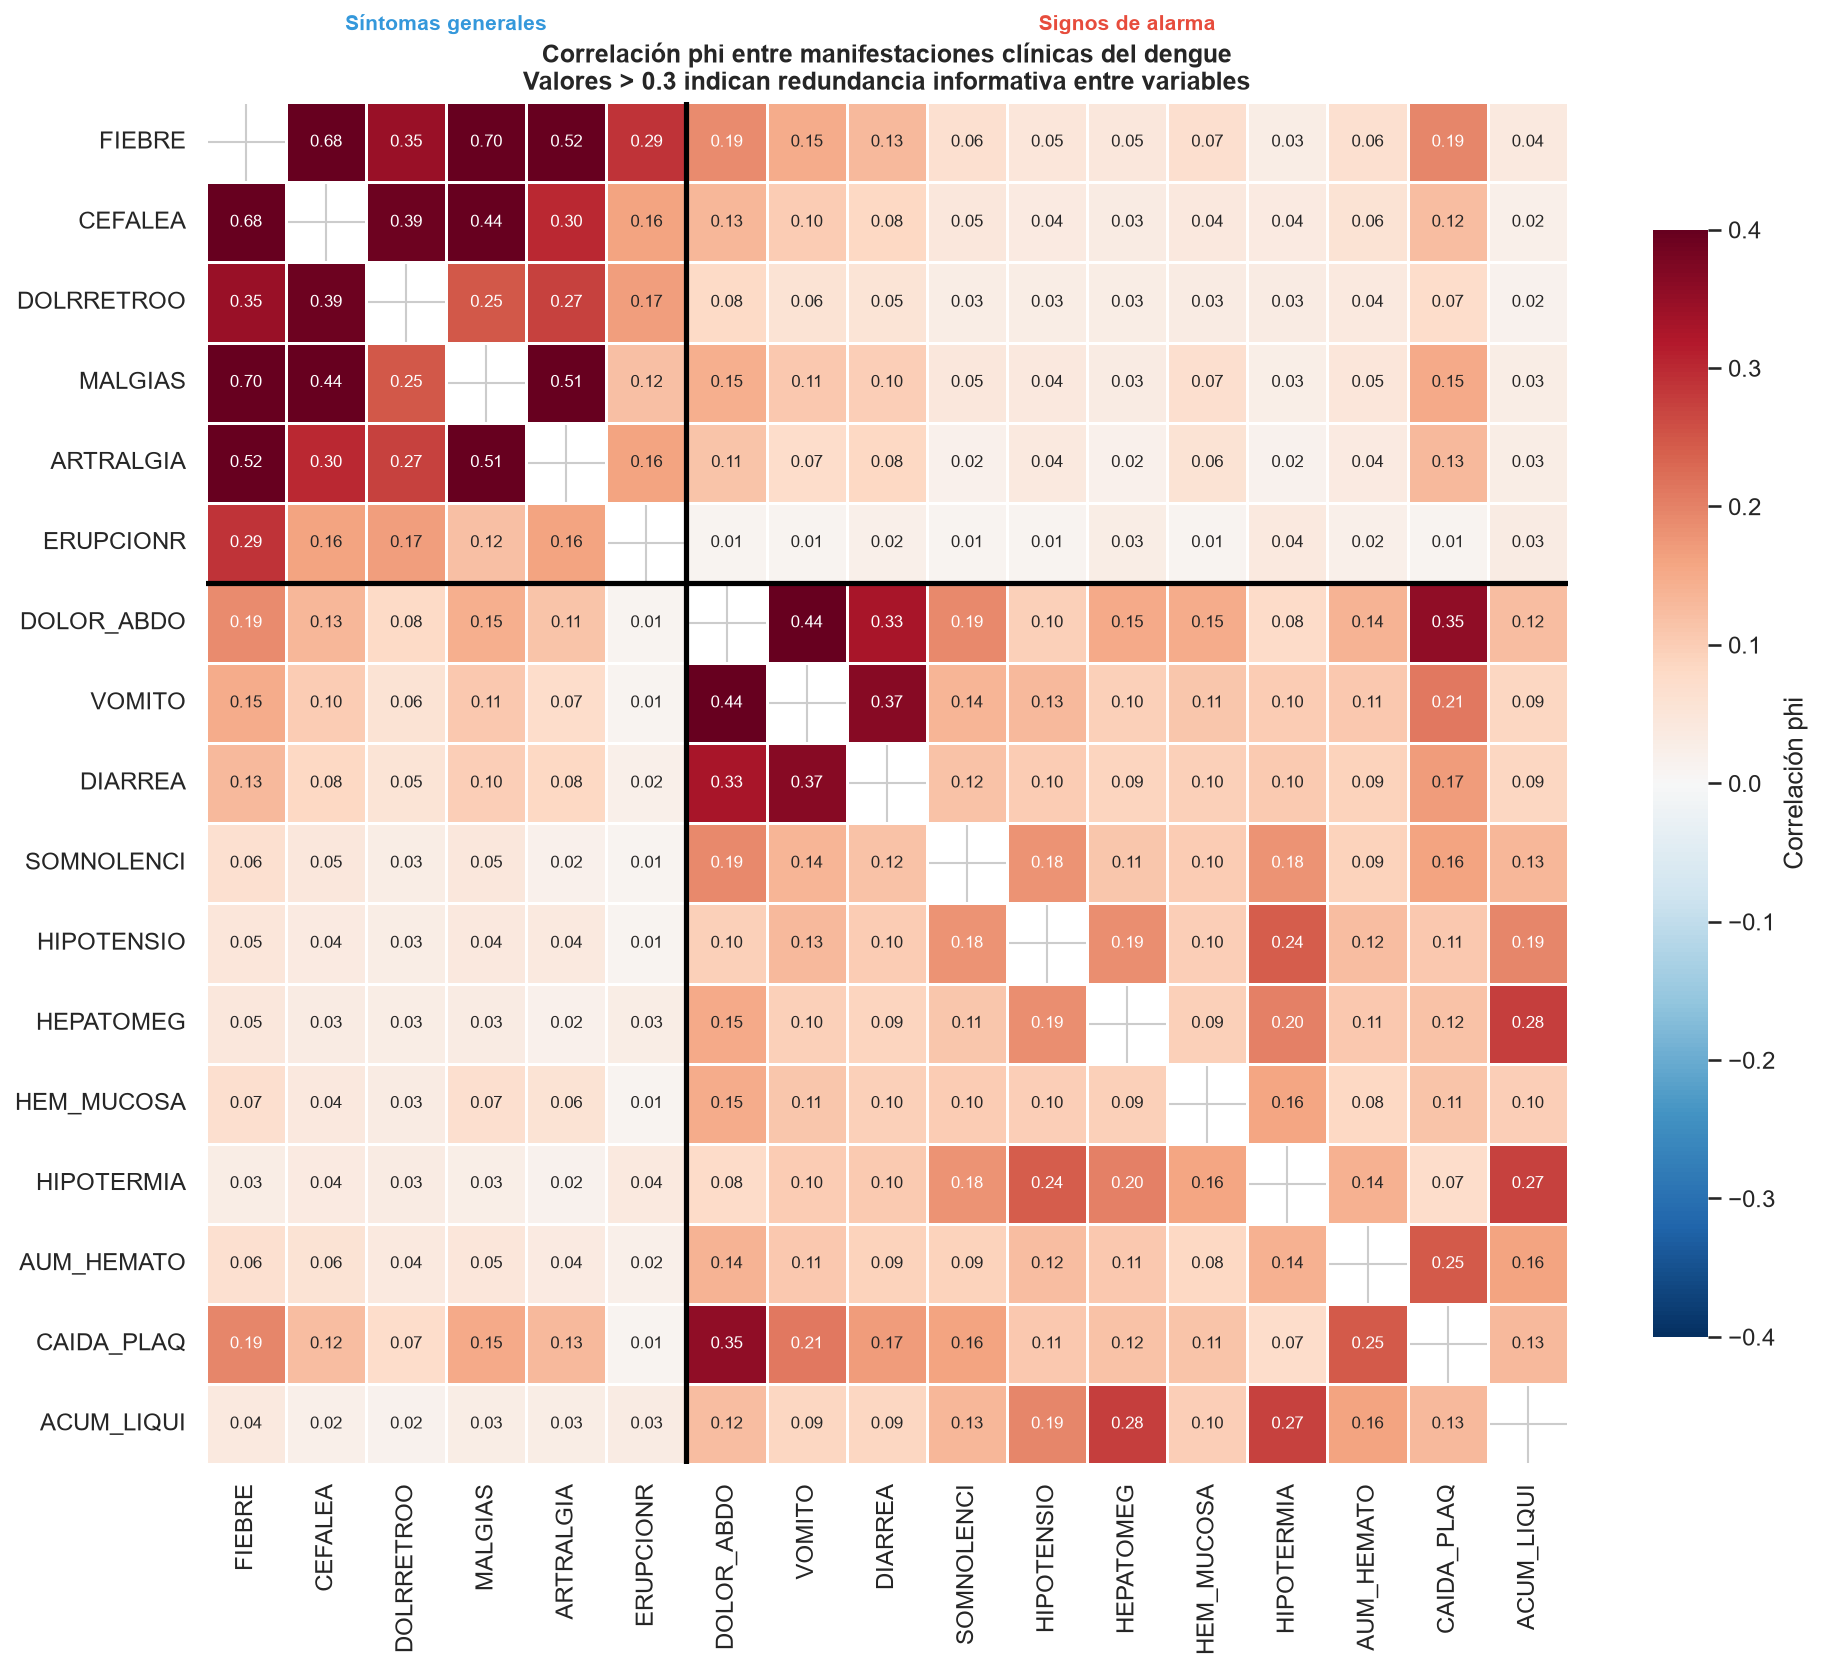

In [12]:
# Matriz de correlación phi entre variables clínicas
# Correlación phi = Pearson para variables 0/1 → comparable entre todos los pares
df_bin  = df[todas].replace({1: 1, 2: 0})
corr_mx = df_bin.corr(method='pearson')

fig, ax = plt.subplots(figsize=(13, 11))
mascara = np.eye(len(corr_mx), dtype=bool)

sns.heatmap(
    corr_mx, mask=mascara,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-0.4, vmax=0.4,
    linewidths=0.5, linecolor='white',
    annot_kws={'size': 8},
    square=True, ax=ax,
    cbar_kws={'shrink': 0.8, 'label': 'Correlación phi'}
)

# Línea divisora entre síntomas generales y signos de alarma
n_s = len(SINTOMAS_GENERALES)
ax.axhline(n_s, color='black', linewidth=2.5)
ax.axvline(n_s, color='black', linewidth=2.5)

ax.text(n_s / 2, -0.9, 'Síntomas generales',
    ha='center', fontsize=10, color=COLORS['sin_signos'], fontweight='bold')
ax.text(n_s + len(SIGNOS_ALARMA) / 2, -0.9, 'Signos de alarma',
    ha='center', fontsize=10, color=COLORS['con_signos'], fontweight='bold')

ax.set_title(
    'Correlación phi entre manifestaciones clínicas del dengue\n'
    'Valores > 0.3 indican redundancia informativa entre variables',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / '05_correlacion_clinica.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()

## 6. Guardado de checkpoints por estrato clínico

Se separan los datos en dos cohortes estratificadas por CLASFINAL:
- **DCSA** (n=12,713): dengue con signos de alarma · 64.8% hospitalización
- **DSSA** (n=15,734): dengue sin signos de alarma · 3.9% hospitalización

El desbalance en DSSA (96/4) exige métricas y estrategias distintas a DCSA (65/35).

In [13]:
# Guardar subcohortes — estos archivos .pkl son la entrada de los notebooks 02 y 03
df_con = df[df['CLASFINAL'].eq('DENGUE CON SIGNOS DE ALARMA')].copy()
df_sin = df[df['CLASFINAL'].eq('DENGUE SIN SIGNOS DE ALARMA')].copy()

joblib.dump(df,     CHECKPOINTS / '01_df_completo.pkl')
joblib.dump(df_con, INTERIM / 'datos_con_signos.pkl')
joblib.dump(df_sin, INTERIM / 'datos_sin_signos.pkl')

print('Checkpoints guardados:')
print(f'  Cohorte completa : {len(df):,} casos')
print(f'  DCSA (con signos): {len(df_con):,} · {df_con[TARGET].mean():.1%} hospitalizados')
print(f'  DSSA (sin signos): {len(df_sin):,} · {df_sin[TARGET].mean():.1%} hospitalizados')
print()
print(f'Figuras exportadas a : {OUT_FIG}')
print(f'Tablas exportadas a  : {OUT_TAB}')

Checkpoints guardados:
  Cohorte completa : 28,626 casos
  DCSA (con signos): 12,713 · 64.8% hospitalizados
  DSSA (sin signos): 15,734 · 3.9% hospitalizados

Figuras exportadas a : D:\Documentos\GitHub\dengue\outputs\figures
Tablas exportadas a  : D:\Documentos\GitHub\dengue\outputs\tables


---

## Hallazgos principales

| Hallazgo | Impacto en el modelado |
|----------|------------------------|
| 31.6% de hospitalización global | Desbalance moderado — manejar con SMOTE o pesos de clase |
| DCSA 64.8% vs DSSA 3.9% hospitalización | Modelos separados por estrato son necesarios |
| Tasa crece 11.7% (2015) → 60.4% (2022) → 31% (2024) | Incluir AÑO como covariable |
| 0 valores nulos en variables clínicas | Sin imputación requerida para estas variables |
| Caída plaquetas y dolor abdominal más prevalentes | Candidatos a mayor importancia en modelos |
| Fiebre 83.5% — alta colinealidad | Evaluar VIF antes de regresión logística |

**Siguiente:** `02_analisis_clinico/02a_analisis_bivariado.ipynb`